# 02 - Audio preprocessing and MFCC feature extraction

This notebook prepares the audio recordings for the classical machine-learning experiments. Background recordings are divided into one-second `silence` examples, the class and split distributions are checked, and audio is standardised to mono at 16 kHz. MFCC summary features are then extracted for the Linear SVM and Random Forest models.

**The dataset exploration notebook must be completed before this stage.** The downloaded recordings and generated index are stored locally and are excluded from GitHub.

## 1. Project paths and imports

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    build_audio_index,
    save_audio_index,
    class_distribution,
    extract_mfcc_features,
    split_feature_arrays,
)

NOTEBOOK_DATA = Path.cwd() / "data" if Path.cwd().name == "notebooks" else PROJECT_ROOT / "notebooks" / "data"
INDEX_PATH = NOTEBOOK_DATA / "processed" / "audio_index.csv"
DATASET_DIR = NOTEBOOK_DATA / "raw" / "speech_commands_v0.02"
PROCESSED_DIR = NOTEBOOK_DATA / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_RATE = 16_000
DURATION_SECONDS = 1.0
N_MFCC = 40

print("Repository root:", PROJECT_ROOT)
print("Speech index:", INDEX_PATH)
print("Extracted dataset:", DATASET_DIR)

Repository root: c:\Users\a\Documents\machine_learning_cycle
Speech index: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\audio_index.csv
Extracted dataset: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\raw\speech_commands_v0.02


## 2. Build the complete index, including silence

In [2]:
audio_index = build_audio_index(
    INDEX_PATH,
    DATASET_DIR,
    silence_stride_seconds=1.0,
)

complete_index_path = save_audio_index(
    audio_index,
    PROCESSED_DIR / "audio_index_with_silence.csv",
)

print(f"Total indexed clips: {len(audio_index):,}")
print("Target classes:", sorted(audio_index["target"].astype(str).unique()))
print("Saved complete index:", complete_index_path)

Total indexed clips: 106,227
Target classes: ['down', 'go', 'left', 'no', 'off', 'on', 'right', 'silence', 'stop', 'unknown', 'up', 'yes']
Saved complete index: c:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\audio_index_with_silence.csv


## 3. Inspect class distribution and official splits

target,down,go,left,no,off,on,right,silence,stop,unknown,up,yes
split,,,,,,,,,,,,
test,406,402,412,405,402,396,396,60,411,6931,425,419
train,3134,3106,3037,3130,2970,3086,3019,277,3111,54074,2948,3228
validation,377,372,352,406,373,363,363,61,350,6278,350,397


,recordings
split,
test,11065
train,85120
validation,10042


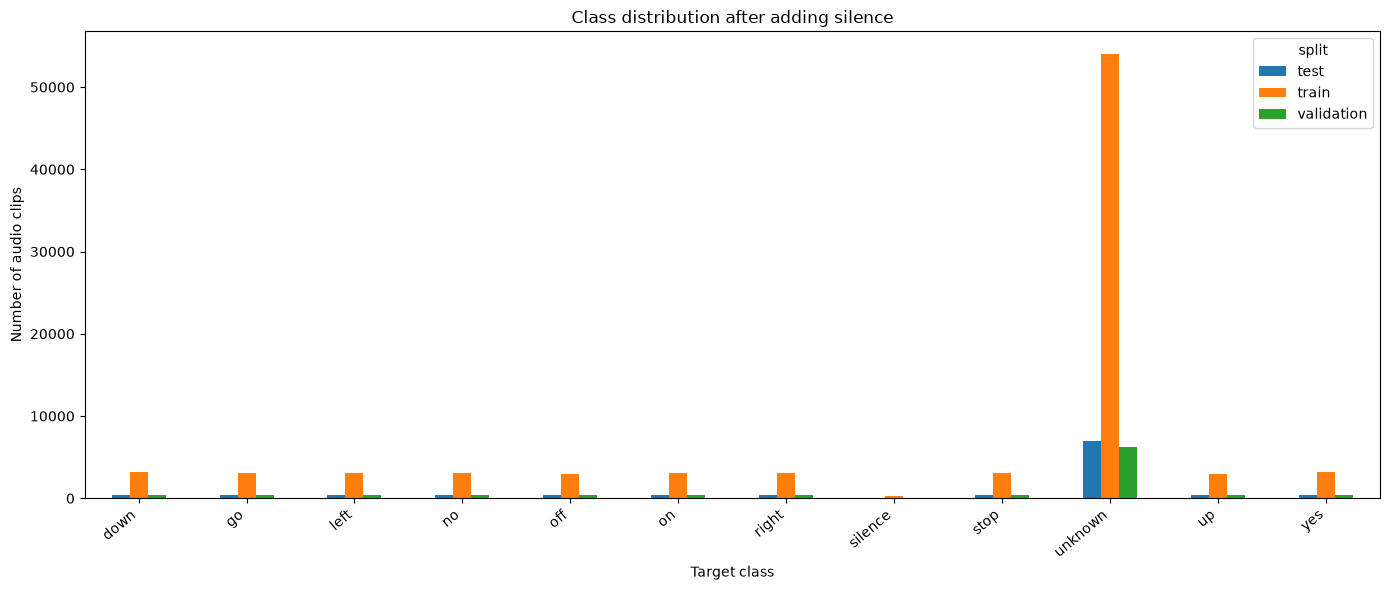

12 target classes and all three data splits are present.


In [3]:
distribution = class_distribution(audio_index)
display(distribution)

split_totals = audio_index.groupby("split", observed=True).size().rename("recordings")
display(split_totals.to_frame())

ax = distribution.T.plot(kind="bar", figsize=(14, 6))
ax.set_title("Class distribution after adding silence")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of audio clips")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

assert set(audio_index["target"].astype(str).unique()) == {
    "yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go", "unknown", "silence"
}, "The index should contain exactly the 12 planned target classes."
assert set(audio_index["split"].astype(str).unique()) == {"train", "validation", "test"}
print("12 target classes and all three data splits are present.")

## 4. Verify silence split isolation

Each background recording is assigned to only one data split. This prevents segments from the same continuous noise recording from appearing in both training and evaluation data.

In [4]:
silence_index = audio_index[audio_index["target"].astype(str) == "silence"].copy()
silence_source_splits = silence_index.groupby("speaker_id", observed=True)["split"].nunique()
assert (silence_source_splits == 1).all(), "A background recording appears in more than one split."
display(
    silence_index.groupby(["split", "speaker_id"], observed=True)
    .size()
    .rename("one_second_segments")
    .reset_index()
)
print("Background recording split-isolation check passed.")

,split,speaker_id,one_second_segments
0,test,white_noise,60
1,train,doing_the_dishes,95
2,train,dude_miaowing,61
3,train,exercise_bike,61
4,train,pink_noise,60
5,validation,running_tap,61


Background recording split-isolation check passed.


## 5. Test MFCC extraction on a small sample

MFCC extraction is first checked on a small sample, with up to five recordings per class and split. The feature dimensions and label alignment are verified before processing the full dataset.

In [5]:
X_preview, y_preview, preview_metadata = extract_mfcc_features(
    audio_index,
    sample_rate=SAMPLE_RATE,
    duration_seconds=DURATION_SECONDS,
    n_mfcc=N_MFCC,
    max_samples_per_class=5,
    random_state=42,
)

print("Preview feature matrix:", X_preview.shape)
print("Preview labels:", pd.Series(y_preview).value_counts().sort_index().to_dict())
assert X_preview.shape[1] == N_MFCC * 2
assert len(X_preview) == len(y_preview) == len(preview_metadata)
assert np.isfinite(X_preview).all(), "MFCC features contain NaN or infinite values."
print("MFCC preview checks passed.")

Extracting MFCCs:   0%|          | 0/180 [00:00<?, ?it/s]

Preview feature matrix: (180, 80)
Preview labels: {'down': 15, 'go': 15, 'left': 15, 'no': 15, 'off': 15, 'on': 15, 'right': 15, 'silence': 15, 'stop': 15, 'unknown': 15, 'up': 15, 'yes': 15}
MFCC preview checks passed.


## 6. Extract MFCC features for the full dataset

MFCC features are extracted for every indexed recording. Each recording is represented by 80 summary values: the mean and standard deviation of 40 MFCC coefficients. Feature scaling and model fitting are applied later within the training pipelines to avoid data leakage.

In [6]:
X, y, feature_metadata = extract_mfcc_features(
    audio_index,
    sample_rate=SAMPLE_RATE,
    duration_seconds=DURATION_SECONDS,
    n_mfcc=N_MFCC,
    max_samples_per_class=None,
    show_progress=True,
)

feature_splits = split_feature_arrays(X, y, feature_metadata)
for split_name, arrays in feature_splits.items():
    print(f"{split_name:10s} X={arrays['X'].shape}, y={arrays['y'].shape}")

assert np.isfinite(X).all(), "Full feature matrix contains NaN or infinite values."
assert X.shape[1] == N_MFCC * 2

Extracting MFCCs:   0%|          | 0/106227 [00:00<?, ?it/s]

train      X=(85120, 80), y=(85120,)
validation X=(10042, 80), y=(10042,)
test       X=(11065, 80), y=(11065,)


## 7. Save the feature arrays locally

In [7]:
feature_output = PROCESSED_DIR / "mfcc_features.npz"
np.savez_compressed(
    feature_output,
    X_train=feature_splits["train"]["X"],
    y_train=feature_splits["train"]["y"],
    X_validation=feature_splits["validation"]["X"],
    y_validation=feature_splits["validation"]["y"],
    X_test=feature_splits["test"]["X"],
    y_test=feature_splits["test"]["y"],
    feature_names=np.array(
        [f"mfcc_{i+1}_{stat}" for stat in ("mean", "std") for i in range(N_MFCC)]
    ),
)
print("Saved feature arrays:", feature_output.resolve())
print("Feature matrix shape:", X.shape)
print("Preprocessing milestone complete.")

Saved feature arrays: C:\Users\a\Documents\machine_learning_cycle\notebooks\data\processed\mfcc_features.npz
Feature matrix shape: (106227, 80)
Preprocessing milestone complete.


## Interpretation and next step

- The prepared dataset contains 12 target classes, including `silence` examples created from background recordings.
- The official training, validation and test assignments are retained.
- Background-noise source recordings are kept within a single split to reduce leakage.
- Each recording is represented by 80 MFCC summary features.
- The feature arrays are saved locally and are not included in the repository.

The next stage compares classical classifiers using the training data for fitting and the validation data for model selection. The test split remains reserved for final evaluation.